In [1]:
#Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 20)

In [14]:
#Loading the file

oni_raw = pd.read_csv('../data/oni.ascii.txt', sep=r'\s+')
oni = oni_raw.copy()   # oni_raw stays untouched as a backup
print(oni.shape)
oni.head()

(920, 4)


,SEAS,YR,TOTAL,ANOM
0,DJF,1950,25.01,-1.32
1,JFM,1950,25.36,-1.20
2,FMA,1950,25.88,-1.12
3,MAM,1950,26.24,-1.08
4,AMJ,1950,26.35,-1.10


In [15]:
#Building a proper date column
season_to_month = {
    'DJF': 1, 'JFM': 2, 'FMA': 3, 'MAM': 4, 'AMJ': 5, 'MJJ': 6,
    'JJA': 7, 'JAS': 8, 'ASO': 9, 'SON': 10, 'OND': 11, 'NDJ': 12,
}

oni['month'] = oni['SEAS'].map(season_to_month)
print('Unmapped seasons:', oni['month'].isna().sum())   # must be 0

oni['date'] = pd.to_datetime(dict(year=oni['YR'], month=oni['month'], day=1))

# Give the columns clearer names and keep only what we need
oni = oni.rename(columns={'ANOM': 'oni', 'TOTAL': 'nino34_sst'})
oni = oni[['date', 'SEAS', 'oni', 'nino34_sst']]
oni.head()

Unmapped seasons: 0


,date,SEAS,oni,nino34_sst
0,1950-01-01,DJF,-1.32,25.01
1,1950-02-01,JFM,-1.20,25.36
2,1950-03-01,FMA,-1.12,25.88
3,1950-04-01,MAM,-1.08,26.24
4,1950-05-01,AMJ,-1.10,26.35


In [11]:
#Quality checks
print('Rows:', len(oni))
print('Date range:', oni['date'].min(), 'to', oni['date'].max())
print('Duplicate dates:', oni['date'].duplicated().sum())
print('Missing values:')
print(oni.isna().sum())

full_range = pd.date_range(oni['date'].min(), oni['date'].max(), freq='MS')
print('Missing months:', len(full_range.difference(oni['date'])))

Rows: 920
Date range: 1950-01-01 00:00:00 to 2026-08-01 00:00:00
Duplicate dates: 0
Missing values:
date          0
SEAS          0
oni           0
nino34_sst    0
month         0
dtype: int64
Missing months: 0


In [16]:
#Load and Clean the SOI data

months = ['JAN','FEB','MAR','APR','MAY','JUN','JUL','AUG','SEP','OCT','NOV','DEC']

soi_wide = pd.read_fwf(
    '../data/soi_raw.txt',
    skiprows=4,            
    nrows=80,              # years 1951 to 2030, anomaly block only
    widths=[4] + [6] * 12, # year = 4 characters, each month = 6 characters
    header=None,
    names=['YEAR'] + months,
)
print(soi_wide.shape)
soi_wide.tail(6)

(80, 13)


,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC
74,2025,0.3,0.9,2.8,0.9,0.7,0.5,1.0,0.7,0.1,1.9,1.8,-0.0
75,2026,1.8,2.4,2.0,-1.1,-1.5,-2.4,-4.0,-1.8,-3.3,-999.9,-999.9,-999.9
76,2027,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9
77,2028,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9
78,2029,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9
79,2030,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9,-999.9


In [17]:
#Convert the missing values to NaN
n_codes = (soi_wide[months] == -999.9).sum().sum()
soi_wide = soi_wide.replace(-999.9, np.nan)

print('Cells converted:', n_codes)
print('NaN cells now:', soi_wide[months].isna().sum().sum())

Cells converted: 51
NaN cells now: 51


In [18]:
#Reshape from wide to long

soi_long = soi_wide.melt(id_vars='YEAR', var_name='month_name', value_name='soi')

month_number = {m: i + 1 for i, m in enumerate(months)}
soi_long['month'] = soi_long['month_name'].map(month_number)

soi_long['date'] = pd.to_datetime(
    dict(year=soi_long['YEAR'], month=soi_long['month'], day=1)
)
soi_long = soi_long.sort_values('date').reset_index(drop=True)
print(soi_long.shape)
soi_long.head()

(960, 5)


,YEAR,month_name,soi,month,date
0,1951,JAN,2.5,1,1951-01-01
1,1951,FEB,1.5,2,1951-02-01
2,1951,MAR,-0.2,3,1951-03-01
3,1951,APR,-0.5,4,1951-04-01
4,1951,MAY,-1.1,5,1951-05-01


In [19]:
#Drop empty future months and check
soi = soi_long.dropna(subset=['soi'])[['date', 'soi']].reset_index(drop=True)

print('Rows:', len(soi))
print('Date range:', soi['date'].min(), 'to', soi['date'].max())
print('Duplicate dates:', soi['date'].duplicated().sum())
print('Missing values:', soi['soi'].isna().sum())

Rows: 909
Date range: 1951-01-01 00:00:00 to 2026-09-01 00:00:00
Duplicate dates: 0
Missing values: 0


In [20]:
#Merge ONI and SOI
enso = pd.merge(oni, soi, on='date', how='inner')
enso = enso.sort_values('date').reset_index(drop=True)

print(enso.shape)
print(enso['date'].min(), 'to', enso['date'].max())
enso.head()

(908, 5)
1951-01-01 00:00:00 to 2026-08-01 00:00:00


,date,SEAS,oni,nino34_sst,soi
0,1951-01-01,DJF,-0.66,25.67,2.5
1,1951-02-01,JFM,-0.36,26.20,1.5
2,1951-03-01,FMA,-0.04,26.96,-0.2
3,1951-04-01,MAM,0.16,27.48,-0.5
4,1951-05-01,AMJ,0.27,27.72,-1.1


In [21]:
#Label El Nino, La Nina and Neutral

def label_simple(x):
    if x >= 0.5:
        return 'El Niño'
    if x <= -0.5:
        return 'La Niña'
    return 'Neutral'

enso['phase_simple'] = enso['oni'].apply(label_simple)

def sustained(flag, n=5):
    # True only where the flag belongs to a run of at least n consecutive True values
    run_id = (flag != flag.shift()).cumsum()
    run_len = flag.groupby(run_id).transform('size')
    return flag & (run_len >= n)

is_el_nino = sustained(enso['oni'] >= 0.5)
is_la_nina = sustained(enso['oni'] <= -0.5)
enso['phase'] = np.select([is_el_nino, is_la_nina], ['El Niño', 'La Niña'], default='Neutral')

print(enso['phase_simple'].value_counts())
print()
print(enso['phase'].value_counts())

phase_simple
Neutral    448
El Niño    234
La Niña    226
Name: count, dtype: int64

phase
Neutral    485
El Niño    215
La Niña    208
Name: count, dtype: int64


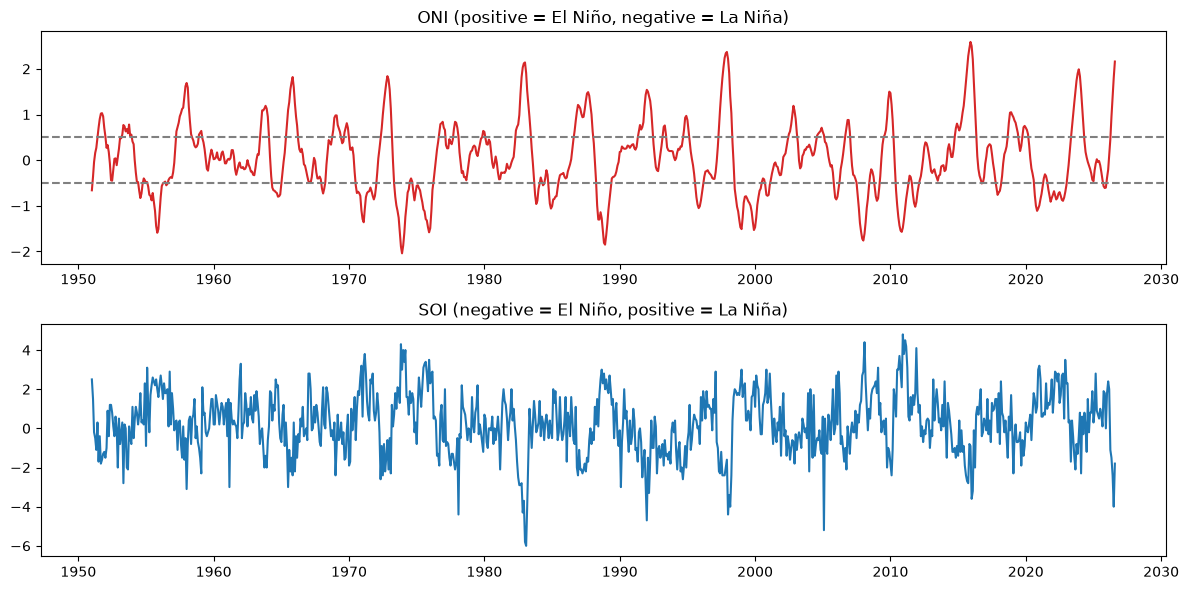

          oni       soi
oni  1.000000 -0.728834
soi -0.728834  1.000000


In [23]:
#checkimg with plot

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].tick_params(labelbottom=True)
ax[0].plot(enso['date'], enso['oni'], color='tab:red')
ax[0].axhline(0.5, ls='--', color='gray')
ax[0].axhline(-0.5, ls='--', color='gray')
ax[0].set_title('ONI (positive = El Niño, negative = La Niña)')

ax[1].plot(enso['date'], enso['soi'], color='tab:blue')
ax[1].set_title('SOI (negative = El Niño, positive = La Niña)')

plt.tight_layout()
plt.show()

print(enso[['oni', 'soi']].corr())

In [24]:
#Save the clean data

enso.to_csv('../data/enso_clean.csv', index=False)

check = pd.read_csv('../data/enso_clean.csv', parse_dates=['date'])
print(check.shape)
print(check.dtypes)

(908, 7)
date            datetime64[us]
SEAS                       str
oni                    float64
nino34_sst             float64
soi                    float64
phase_simple               str
phase                      str
dtype: object


## Cleaning log

**ONI**
- Loaded by whitespace separator. 920 rows, no missing values, no duplicates, no missing months.
- Converted SEAS (3-month season) to its middle month and built a datetime column.
- Renamed ANOM to oni and TOTAL to nino34_sst.

**SOI**
- File has two blocks (anomaly and standardized). Used only the anomaly block.
- Some values run together with no spaces, so I read the file by fixed column width.
- Converted the -999.9 missing code to NaN (51 cells, all future months).
- Reshaped from wide to long and built a datetime column.
- Dropped the empty future months, leaving 909 rows.

**Merge**
- Inner join on date. Lost 1950 (SOI starts 1951) and Sep 2026 (no ONI yet).
- Final dataset: 908 monthly rows, Jan 1951 to Aug 2026.

**Labels**
- phase_simple: one month vs the +/-0.5 threshold.
- phase: threshold must hold for 5+ consecutive months (simplified from NOAA's rule).